### Cybersecurity Intrusion Detection

Introduction

In this project, we aim to predict and detect cybersecurity intrusions by analyzing various network and user activity features such as network packet size, protocol type, encryption used, failed logins, browser type, and more.

Understanding the key indicators of cyber-attacks can help organizations strengthen their security systems, reduce vulnerabilities, and respond to threats proactively. With the power of data science and machine learning, we can uncover patterns of intrusion and build accurate models for real-time threat detection.

We will perform the following steps in this notebook:
- Load and clean the dataset
- Explore and visualize the data
- Train and evaluate machine learning models


Let’s get started

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# import the necessary libraries

ModuleNotFoundError: No module named 'numpy'

In [ ]:
Data = pd.read_csv('/kaggle/input/cybersecurity-intrusion-detection-dataset/cybersecurity_intrusion_data.csv')
Data.head()

# load the dataset

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


In [ ]:
Data.drop(columns=['session_id'],inplace=True)

# drop the unnecessary column

In [ ]:
print("Shape:", Data.shape)
Data.info()

Shape: (9537, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   network_packet_size  9537 non-null   int64  
 1   protocol_type        9537 non-null   object 
 2   login_attempts       9537 non-null   int64  
 3   session_duration     9537 non-null   float64
 4   encryption_used      7571 non-null   object 
 5   ip_reputation_score  9537 non-null   float64
 6   failed_logins        9537 non-null   int64  
 7   browser_type         9537 non-null   object 
 8   unusual_time_access  9537 non-null   int64  
 9   attack_detected      9537 non-null   int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 745.2+ KB


In [ ]:
Data.describe(include=[np.number]).T.head(20)


,count,mean,std,min,25%,50%,75%,max
network_packet_size,9537.0,500.430639,198.379364,64.000000,365.000000,499.000000,635.000000,1285.000000
login_attempts,9537.0,4.032086,1.963012,1.000000,3.000000,4.000000,5.000000,13.000000
session_duration,9537.0,792.745312,786.560144,0.500000,231.953006,556.277457,1105.380602,7190.392213
ip_reputation_score,9537.0,0.331338,0.177175,0.002497,0.191946,0.314778,0.453388,0.924299
failed_logins,9537.0,1.517773,1.033988,0.000000,1.000000,1.000000,2.000000,5.000000
unusual_time_access,9537.0,0.149942,0.357034,0.000000,0.000000,0.000000,0.000000,1.000000
attack_detected,9537.0,0.447101,0.497220,0.000000,0.000000,0.000000,1.000000,1.000000


In [ ]:
Data.isnull().sum()

# check for missing values  

network_packet_size       0
protocol_type             0
login_attempts            0
session_duration          0
encryption_used        1966
ip_reputation_score       0
failed_logins             0
browser_type              0
unusual_time_access       0
attack_detected           0
dtype: int64

In [ ]:
(Data.isnull().sum() / len(Data)) * 100

network_packet_size     0.000000
protocol_type           0.000000
login_attempts          0.000000
session_duration        0.000000
encryption_used        20.614449
ip_reputation_score     0.000000
failed_logins           0.000000
browser_type            0.000000
unusual_time_access     0.000000
attack_detected         0.000000
dtype: float64

In [ ]:
Data['encryption_used'] = Data['encryption_used'].fillna(Data['encryption_used'].mode()[0])

In [ ]:
print("Shape:", Data.shape)
Data.info()

Shape: (9537, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   network_packet_size  9537 non-null   int64  
 1   protocol_type        9537 non-null   object 
 2   login_attempts       9537 non-null   int64  
 3   session_duration     9537 non-null   float64
 4   encryption_used      9537 non-null   object 
 5   ip_reputation_score  9537 non-null   float64
 6   failed_logins        9537 non-null   int64  
 7   browser_type         9537 non-null   object 
 8   unusual_time_access  9537 non-null   int64  
 9   attack_detected      9537 non-null   int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 745.2+ KB


In [ ]:
Data.duplicated().sum()

# check for duplicates values

0

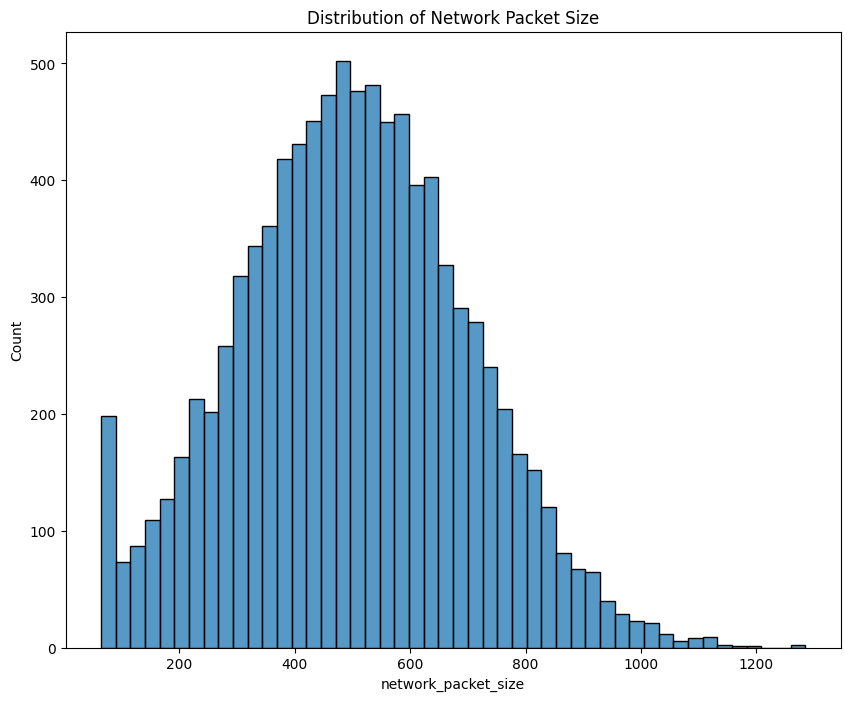

In [ ]:
plt.figure(figsize=(10,8))
sns.histplot(x='network_packet_size',data=Data)
plt.title('Distribution of Network Packet Size')
plt.show()

# explore the data with histplot

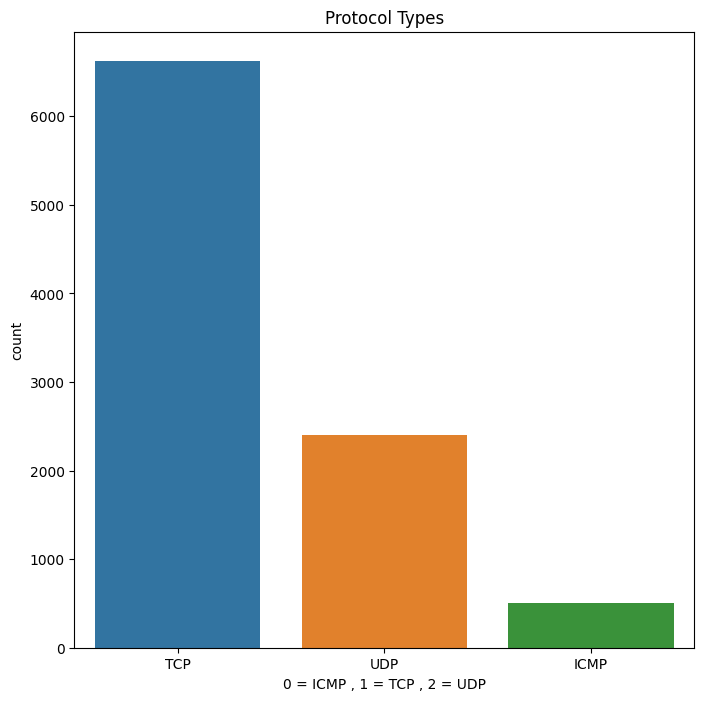

In [ ]:
plt.figure(figsize=(8,8))
sns.countplot(x='protocol_type',data=Data)
plt.title('Protocol Types')
plt.xlabel('0 = ICMP , 1 = TCP , 2 = UDP')
plt.show()

# explore the data with countplot

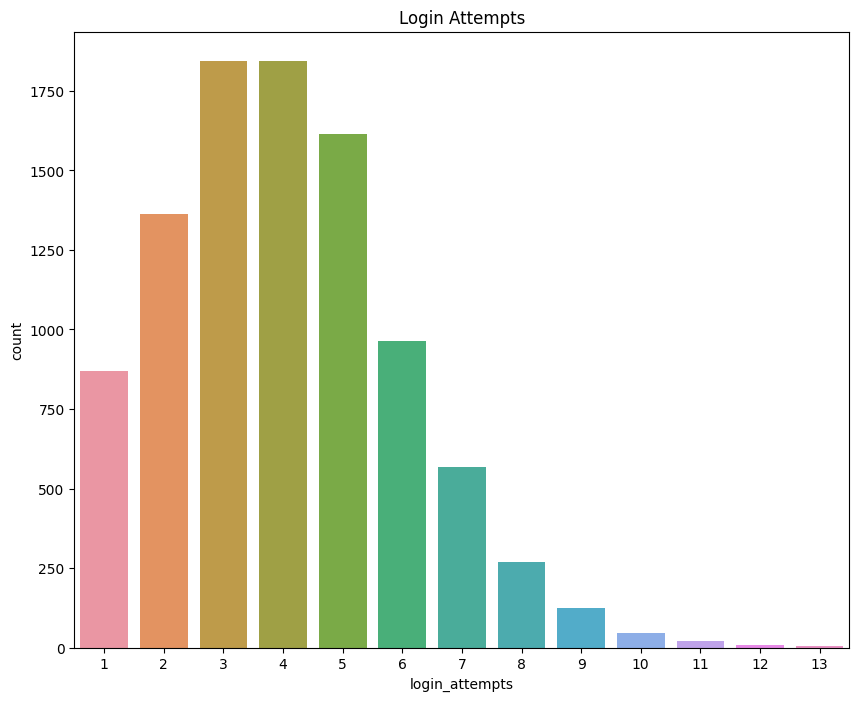

In [ ]:
plt.figure(figsize=(10,8))
sns.countplot(x='login_attempts',data=Data)
plt.title('Login Attempts')
plt.show()

# explore the data with countplot

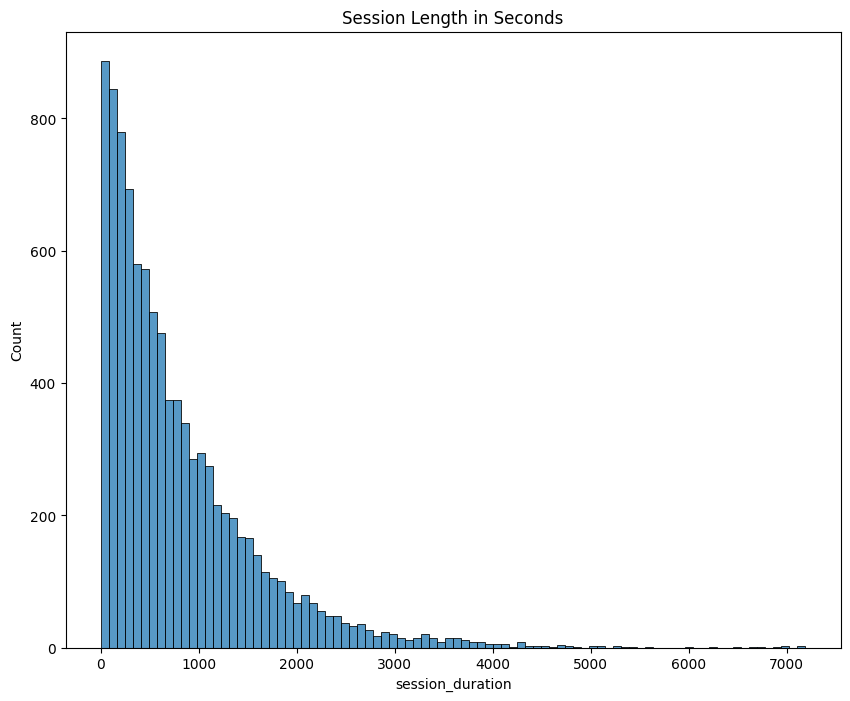

In [ ]:
plt.figure(figsize=(10,8))
sns.histplot(x='session_duration',data=Data)
plt.title('Session Length in Seconds')
plt.show()

# explore the data with histplot

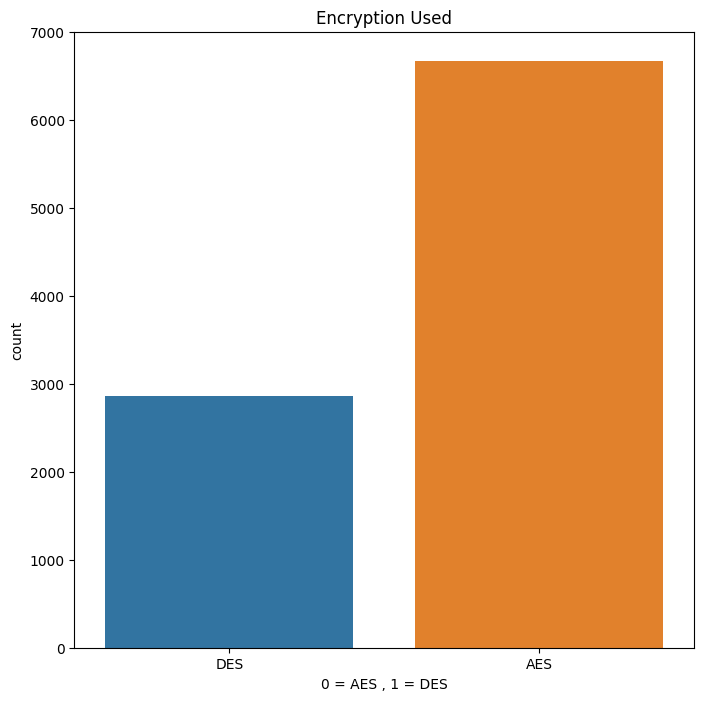

In [ ]:
plt.figure(figsize=(8,8))
sns.countplot(x='encryption_used',data=Data)
plt.title('Encryption Used')
plt.xlabel('0 = AES , 1 = DES')
plt.show()

# explore the data with countplot

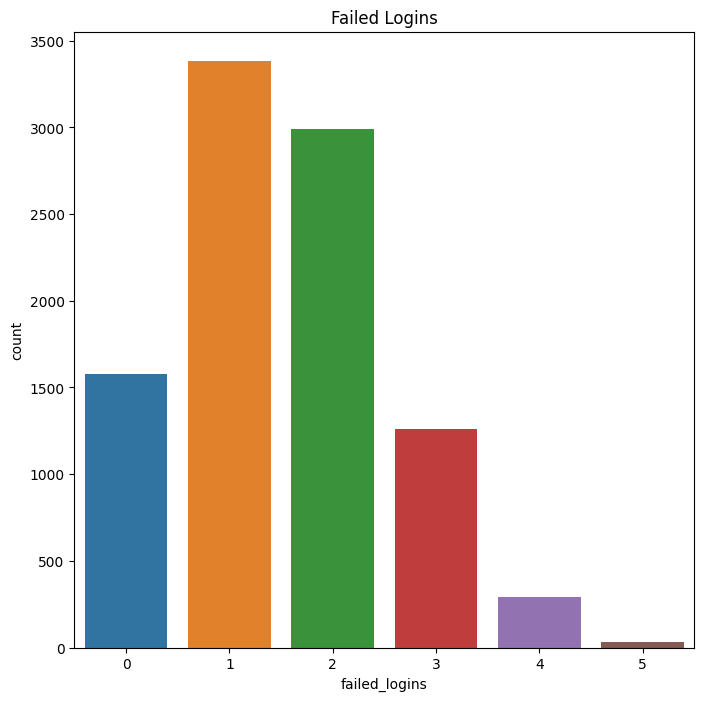

In [ ]:
plt.figure(figsize=(8,8))
sns.countplot(x='failed_logins',data=Data)
plt.title('Failed Logins')
plt.show()

# explore the data with countplot

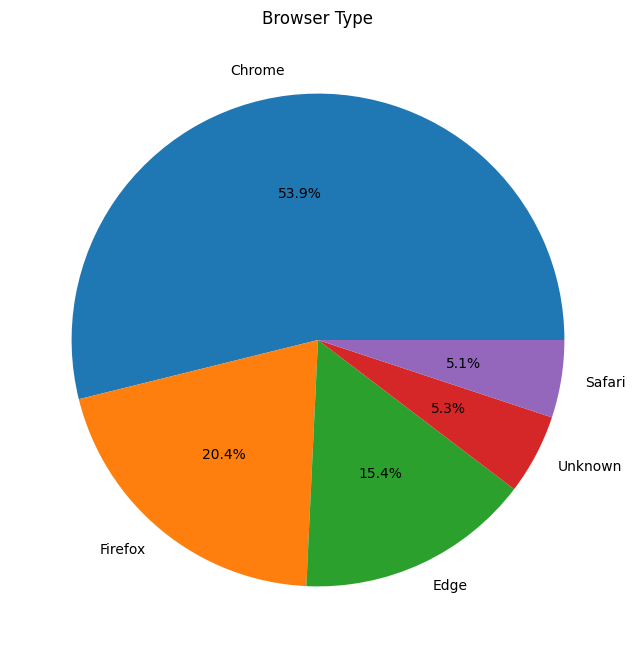

In [ ]:
value = Data['browser_type'].value_counts()

Labels = ['Chrome','Firefox','Edge','Unknown','Safari']

plt.figure(figsize=(8,8))
plt.pie(value,autopct='%1.1f%%',labels=Labels)
plt.title('Browser Type')
plt.show()

# explore the data with pieplott

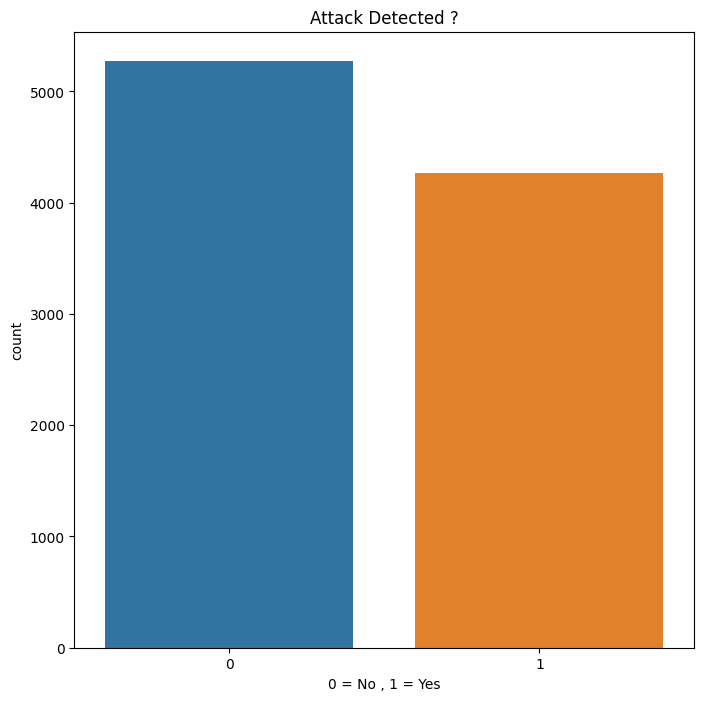

In [ ]:
plt.figure(figsize=(8,8))
sns.countplot(x='attack_detected',data=Data)
plt.title('Attack Detected ?')
plt.xlabel('0 = No , 1 = Yes')
plt.show()

# explore the data with countplot

**converts categorical  columns into numbers**

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

elements = ['protocol_type','encryption_used','browser_type']
for elem in elements:
  Data[elem] = encoder.fit_transform(Data[elem])

# preprocess the data

In [ ]:
Data.head()

,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,599,1,4,492.983263,1,0.606818,1,1,0,1
1,472,1,3,1557.996461,1,0.301569,0,2,0,0
2,629,1,3,75.044262,1,0.739164,2,0,0,1
3,804,2,4,601.248835,1,0.123267,0,4,0,1
4,453,1,5,532.540888,0,0.054874,1,2,0,0


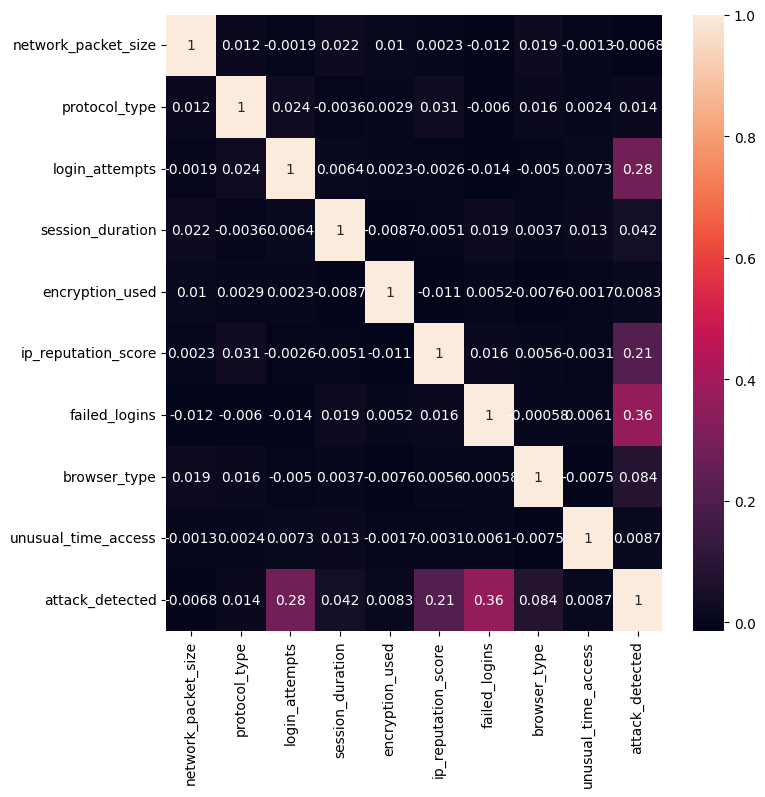

In [ ]:
plt.figure(figsize=(8,8))
sns.heatmap(Data.corr(),annot=True)
plt.show()

# explore the data with heatmap

In [ ]:
x = Data.drop(columns=['attack_detected'],axis=1)
y = Data['attack_detected']

In [ ]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.3,random_state=42,stratify=y)

# split the data

In [ ]:
from sklearn.ensemble import RandomForestClassifier

Model = RandomForestClassifier()
Model.fit(x_train,y_train)

# train the model

RandomForestClassifier()

In [ ]:
y_pred = Model.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test,y_pred)
print(f"""The Accuracy : {accuracy * 100:.2f}%""")

# evaluate the model with accuracy score

The Accuracy : 88.43%


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

# evaluate the model with classification report

              precision    recall  f1-score   support

           0       0.83      0.99      0.90      1582
           1       0.99      0.75      0.85      1280

    accuracy                           0.88      2862
   macro avg       0.91      0.87      0.88      2862
weighted avg       0.90      0.88      0.88      2862



In [ ]:
print(f"""Train Score : {Model.score(x_train,y_train) * 100:.2f}%""")
print(f"""Test Score : {Model.score(x_test,y_test) * 100:.2f}%""")

# display training and test accuracy

Train Score : 100.00%
Test Score : 88.43%


In [ ]:
importanc = Model.feature_importances_
columns = x.columns

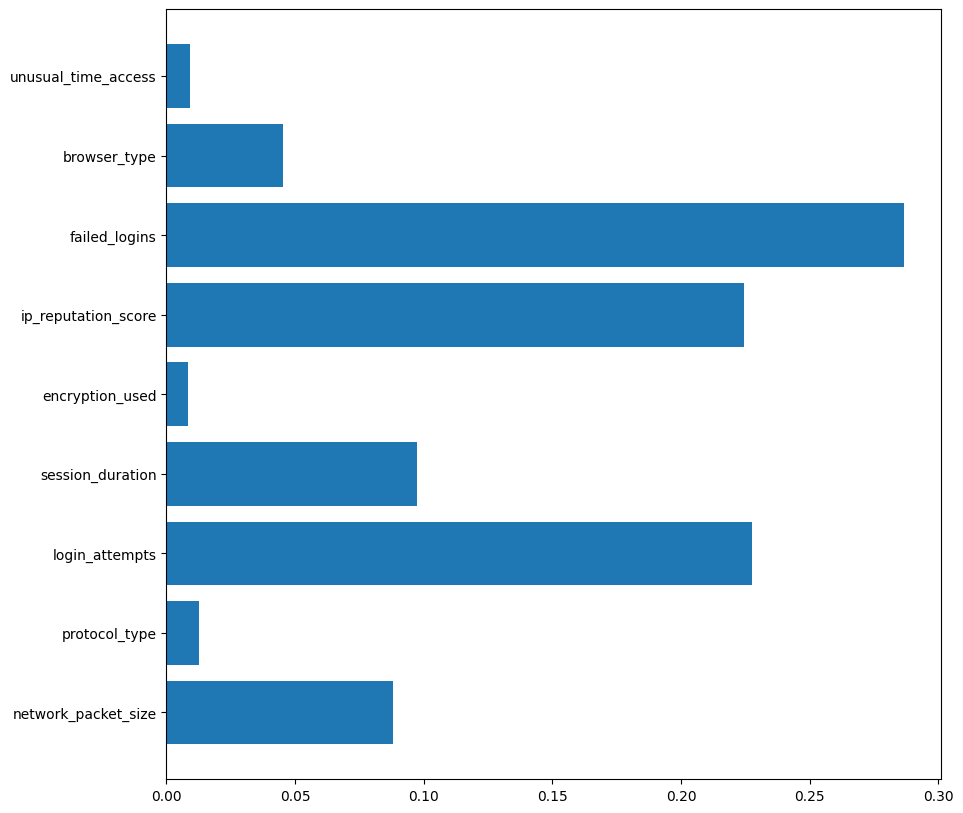

In [ ]:
plt.figure(figsize=(10,10))
plt.barh(columns,importanc)
plt.show()

# Visualize feature importance

In [ ]:
import joblib

joblib.dump(model, "model.pkl")